<div dir="rtl">

# آزمایشگاه ۴ (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">lab4</code>): یادگیری نظارت‌شده، مدل پایه (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Baseline</code>) و معیارها
**درس:** آزمایشگاه هوش مصنوعی (تحویل گام ۴ — پیش از جلسه هفتم)  
**پروژه گروه ۳:** مسیریاب هوشمند شهری در شبکه دوبعدی (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">City Router on 2D Grid</code>)  
**عضو این مخزن:** **سینا محمد پورپورانی** (مسئول مستندسازی <bdi dir="ltr">(Documentation)</bdi>)  
**چالش انتخابی این عضو:** منحنی عمق درخت <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">1..10</code> + معیار <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">f1_score</code>  

</div>

## <bdi dir="ltr">Cell 1: Data and labels (512 positions)</bdi>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

memo = {}                                    # remember answers so we never compute a position twice

def wins(piles):
    """True if the player to move wins Nim from this position (both play perfectly)."""
    if piles in memo:
        return memo[piles]
    result = False
    for i, n in enumerate(piles):
        for take in range(1, n + 1):
            nxt = piles[:i] + (n - take,) + piles[i + 1:]
            if not wins(nxt):                # a move that leaves the opponent in a losing position
                result = True
    memo[piles] = result
    return result

rows = []
for a in range(8):
    for b in range(8):
        for c in range(8):
            rows.append({"p1": a, "p2": b, "p3": c, "loses": not wins((a, b, c))})

df = pd.DataFrame(rows)                      # one row = one position; label "loses" = the player to move loses
print(df.shape)
print(df["loses"].value_counts())
print(df.head())

(512, 4)
loses
False    448
True      64
Name: count, dtype: int64
   p1  p2  p3  loses
0   0   0   0   True
1   0   0   1  False
2   0   0   2  False
3   0   0   3  False
4   0   0   4  False


## <bdi dir="ltr">Cell 2: Train/test split and the baseline (by hand)</bdi>

In [2]:
rng = np.random.default_rng(0)
order = rng.permutation(len(df))             # shuffled row numbers
n_train = int(0.7 * len(df))                 # 70% train, 30% test
train = df.iloc[order[:n_train]]
test = df.iloc[order[n_train:]]

X_train = train[["p1", "p2", "p3"]].to_numpy()
y_train = train["loses"].to_numpy()
X_test = test[["p1", "p2", "p3"]].to_numpy()
y_test = test["loses"].to_numpy()

baseline = np.zeros(len(y_test), dtype=bool)     # baseline: always say "the player wins" (loses = False)
print("train rows:", len(train), "  test rows:", len(test))
print("baseline accuracy:", round((baseline == y_test).mean(), 3))

train rows: 358   test rows: 154
baseline accuracy: 0.883


## <bdi dir="ltr">Cell 3: k-NN from scratch</bdi>

In [3]:
def knn_predict(x, k=3):
    distances = np.abs(X_train - x).sum(axis=1)          # Manhattan distance to every training row
    nearest = np.argsort(distances, kind="stable")[:k]   # the k closest rows
    return y_train[nearest].mean() > 0.5                 # majority vote

pred = np.array([knn_predict(x) for x in X_test])
print("k-NN (from scratch) accuracy:", round((pred == y_test).mean(), 3))

k-NN (from scratch) accuracy: 0.792


## <bdi dir="ltr">Cell 4: Metrics by hand</bdi>

In [4]:
tp = ((pred == True) & (y_test == True)).sum()      # predicted "loses" and it really loses
fp = ((pred == True) & (y_test == False)).sum()     # predicted "loses" but it wins
fn = ((pred == False) & (y_test == True)).sum()     # missed a losing position
tn = ((pred == False) & (y_test == False)).sum()    # predicted "wins" and it wins

accuracy = (tp + tn) / len(y_test)
precision = tp / (tp + fp) if tp + fp > 0 else 0
recall = tp / (tp + fn) if tp + fn > 0 else 0
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")
print(f"accuracy={accuracy:.3f}  precision={precision:.3f}  recall={recall:.3f}")

TP=0  FP=14  FN=18  TN=122
accuracy=0.792  precision=0.000  recall=0.000


# <bdi dir="ltr">Part 2: the same project with scikit-learn</bdi>

## <bdi dir="ltr">Cell 5: Four models, same metrics</bdi>

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

X = df[["p1", "p2", "p3"]]
y = df["loses"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

models = {
    "baseline (always wins)": DummyClassifier(strategy="most_frequent"),
    "k-NN (k=3)": KNeighborsClassifier(n_neighbors=3, metric="manhattan"),
    "decision tree": DecisionTreeClassifier(random_state=0),
    "logistic regression": LogisticRegression(max_iter=1000),
}
results = []
for name, model in models.items():
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    results.append({"model": name,
                    "accuracy": accuracy_score(y_te, pred),
                    "precision": precision_score(y_te, pred, zero_division=0),
                    "recall": recall_score(y_te, pred, zero_division=0)})

table1 = pd.DataFrame(results).round(3)
print(table1)

                    model  accuracy  precision  recall
0  baseline (always wins)     0.877        0.0     0.0
1              k-NN (k=3)     0.773        0.0     0.0
2           decision tree     0.734        0.0     0.0
3     logistic regression     0.877        0.0     0.0


## <bdi dir="ltr">Cell 6: Feature engineering with nim_sum</bdi>

In [6]:
df["nim_sum"] = df["p1"] ^ df["p2"] ^ df["p3"]       # a new feature made from the old ones
X2 = df[["p1", "p2", "p3", "nim_sum"]]
X2_tr, X2_te, y2_tr, y2_te = train_test_split(X2, y, test_size=0.3, random_state=0, stratify=y)

results2 = []
for name, model in models.items():
    model.fit(X2_tr, y2_tr)
    pred = model.predict(X2_te)
    results2.append({"model": name,
                     "accuracy": accuracy_score(y2_te, pred),
                     "precision": precision_score(y2_te, pred, zero_division=0),
                     "recall": recall_score(y2_te, pred, zero_division=0)})

table2 = pd.DataFrame(results2).round(3)
print(table2)

                    model  accuracy  precision  recall
0  baseline (always wins)     0.877      0.000   0.000
1              k-NN (k=3)     0.942      0.708   0.895
2           decision tree     1.000      1.000   1.000
3     logistic regression     1.000      1.000   1.000


## <bdi dir="ltr">Cell 7: Overfitting curve (k-NN)</bdi>

    k  train_acc  test_acc
0   1      1.000     0.760
1   3      0.816     0.773
2   5      0.855     0.838
3   7      0.874     0.877
4   9      0.872     0.877
5  11      0.874     0.864
6  15      0.872     0.870


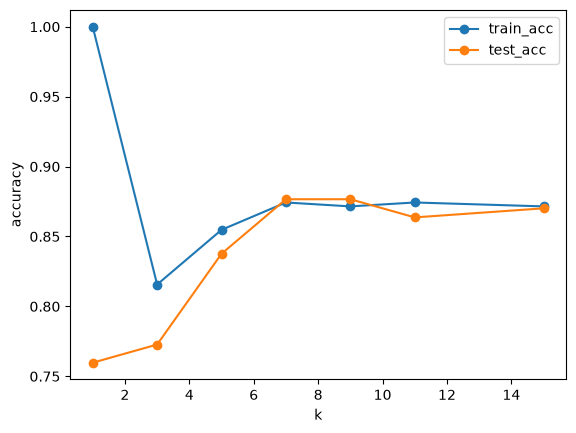

In [7]:
curve = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    knn = KNeighborsClassifier(n_neighbors=k, metric="manhattan").fit(X_tr, y_tr)
    curve.append({"k": k, "train_acc": knn.score(X_tr, y_tr), "test_acc": knn.score(X_te, y_te)})

curve = pd.DataFrame(curve)
print(curve.round(3))
curve.plot(x="k", y=["train_acc", "test_acc"], marker="o")
plt.ylabel("accuracy")
plt.show()

## <bdi dir="ltr">Cell 8: Confusion matrix</bdi>

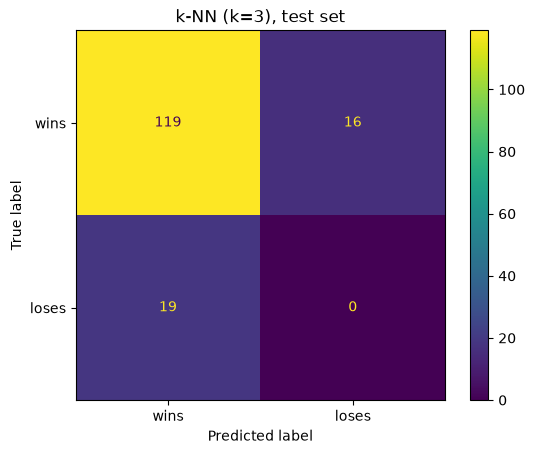

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

knn = KNeighborsClassifier(n_neighbors=3, metric="manhattan").fit(X_tr, y_tr)
ConfusionMatrixDisplay.from_estimator(knn, X_te, y_te, display_labels=["wins", "loses"])
plt.title("k-NN (k=3), test set")
plt.show()

<div dir="rtl">

## تفسیر نتایج آزمایشگاه ۴ (سینا محمد پورپورانی — مستندسازی: نتایج و محدودیت‌ها)

بر اساس الگوی رسمی **مشاهده، دلیل، نتیجه**، خروجی‌های <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">lab4</code> از دید ثبت محدودیت‌ها چنین جمع‌بندی می‌شود:

| ردیف | مشاهده | دلیل | نتیجه |
| :---: | :--- | :--- | :--- |
| ۱ | مدل پایه اکثریت («همیشه می‌برد») بدون یادگیری دقت <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.883</code> (دستی) و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.877</code> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">sklearn</code>) دارد ولی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Recall = 0.000</code> است | از ۵۱۲ وضعیت بازی فقط ۶۴ حالت (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">12.5%</code>) بازنده است و ۴۴۸ حالت برنده است | **محدودیت دقت در کلاس نامتوازن:** <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Accuracy</code> بدون <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Recall</code> و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">F1</code> گمراه‌کننده است |
| ۲ | <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">k-NN</code> دستی روی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">(p1, p2, p3)</code> دقت <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.792</code> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">TP=0, FP=14, FN=18, TN=122</code>) و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Recall = 0.000</code> گرفت | همسایه‌های نزدیک در مختصات <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">(p1, p2, p3)</code> برچسب متضاد دارند و ساختار شطرنجی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">XOR</code> دیده نمی‌شود | **محدودیت ویژگی خام:** مدل مبتنی بر فاصله خام از خط پایه اکثریت هم ضعیف‌تر عمل کرد |
| ۳ | افزودن <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">nim_sum = p1 ^ p2 ^ p3</code> مدل درخت و رگرسیون لجستیک را به <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">1.000</code> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">F1=1.000</code>) و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">k-NN</code> را به <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">F1=0.791</code> رساند | قانون بیتی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">nim_sum == 0</code> همان شرط ریاضی باخت است که فضای حالت را خطی جدا می‌کند | انتخاب ویژگی صحیح اثر بسیار بیشتری از پیچیدگی مدل دارد |
| ۴ | در چالش <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">max_depth</code> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">1..10</code>) روی داده خام، دقت آموزش به <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.947</code> رفت اما آزمون تا <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.740</code> سقوط کرد (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">F1=0.000</code>) | درخت عمیق روی ویژگی ناکافی، استثناهای آموزش را حفظ کرده است | ثبت شکاف آموزش و آزمون برای شناسایی محدودیت تعمیم ضروری است |

</div>

<div dir="rtl">

---
## چالش توسعه (سینا محمد پورپورانی): افزودن معیار <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">f1_score</code> و منحنی عمق درخت <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">max_depth</code> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">1..10</code>)
از زاویه مستندسازی نتایج و محدودیت‌ها، معیار <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">f1_score</code> به جداول مقایسه اضافه می‌شود و شکاف بیش‌برازش درخت تصمیم در عمق‌های <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">1</code> تا <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">10</code> رسم می‌گردد.

</div>

=== Table 1 with F1 (Raw p1, p2, p3) ===


                 model  accuracy  precision  recall  f1
baseline (always wins)     0.877        0.0     0.0 0.0
            k-NN (k=3)     0.773        0.0     0.0 0.0
         decision tree     0.734        0.0     0.0 0.0
   logistic regression     0.877        0.0     0.0 0.0

=== Table 2 with F1 (+ nim_sum) ===


                 model  accuracy  precision  recall    f1
baseline (always wins)     0.877      0.000   0.000 0.000
            k-NN (k=3)     0.942      0.708   0.895 0.791
         decision tree     1.000      1.000   1.000 1.000
   logistic regression     1.000      1.000   1.000 1.000



=== Decision Tree max_depth Curve (1..10) ===
 max_depth  raw_train  raw_test  fe_train  fe_test
         1      0.874     0.877       1.0      1.0
         2      0.874     0.877       1.0      1.0
         3      0.874     0.877       1.0      1.0
         4      0.877     0.870       1.0      1.0
         5      0.877     0.870       1.0      1.0
         6      0.877     0.870       1.0      1.0
         7      0.885     0.844       1.0      1.0
         8      0.905     0.818       1.0      1.0
         9      0.922     0.773       1.0      1.0
        10      0.947     0.740       1.0      1.0


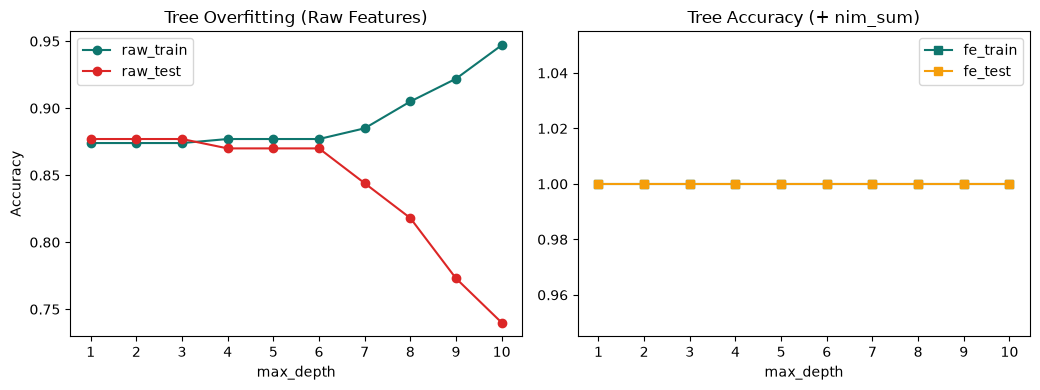

In [9]:
# چالش سینا: F1 score + منحنی max_depth درخت تصمیم از 1 تا 10
from sklearn.metrics import f1_score

def eval_with_f1(Xtr_s, Xte_s, ytr_s, yte_s):
    out = []
    for m_name, clf in models.items():
        clf.fit(Xtr_s, ytr_s)
        pr = clf.predict(Xte_s)
        out.append({
            "model": m_name,
            "accuracy": accuracy_score(yte_s, pr),
            "precision": precision_score(yte_s, pr, zero_division=0),
            "recall": recall_score(yte_s, pr, zero_division=0),
            "f1": f1_score(yte_s, pr, zero_division=0),
        })
    return pd.DataFrame(out).round(3)

print("=== Table 1 with F1 (Raw p1, p2, p3) ===")
print(eval_with_f1(X_tr, X_te, y_tr, y_te).to_string(index=False))
print("\n=== Table 2 with F1 (+ nim_sum) ===")
print(eval_with_f1(X2_tr, X2_te, y2_tr, y2_te).to_string(index=False))

depth_logs = []
for d in range(1, 11):
    dt_a = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_tr, y_tr)
    dt_b = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X2_tr, y2_tr)
    depth_logs.append({
        "max_depth": d,
        "raw_train": dt_a.score(X_tr, y_tr),
        "raw_test": dt_a.score(X_te, y_te),
        "fe_train": dt_b.score(X2_tr, y2_tr),
        "fe_test": dt_b.score(X2_te, y2_te),
    })

depth_tbl = pd.DataFrame(depth_logs).round(3)
print("\n=== Decision Tree max_depth Curve (1..10) ===")
print(depth_tbl.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4))
depth_tbl.plot(x="max_depth", y=["raw_train", "raw_test"], marker="o", ax=ax[0], color=["#0f766e", "#dc2626"])
ax[0].set_title("Tree Overfitting (Raw Features)")
ax[0].set_xticks(range(1, 11))
ax[0].set_ylabel("Accuracy")
depth_tbl.plot(x="max_depth", y=["fe_train", "fe_test"], marker="s", ax=ax[1], color=["#0f766e", "#f59e0b"])
ax[1].set_title("Tree Accuracy (+ nim_sum)")
ax[1].set_xticks(range(1, 11))
plt.tight_layout()
plt.show()


<div dir="rtl">

### ثبت نتایج و محدودیت چالش توسعه: <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">F1</code> و منحنی عمق درخت (سینا محمد پورپورانی)
در این چالش دو خروجی تکمیلی برای گزارش مستندات ثبت شد:
1. افزودن <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">f1_score(..., zero_division=0)</code> ثابت کرد بدون <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">nim_sum</code> هر ۴ مدل <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">F1 = 0.000</code> دارند و اختلاف ظاهری <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">Accuracy</code> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.734</code> تا <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.877</code>) توهم عملکرد است.
2. منحنی <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">max_depth</code> (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">1</code> تا <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">10</code>) روی داده خام نشان داد از عمق <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">7</code> به بعد دقت آموزش بالا می‌رود (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.947</code> در عمق <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">10</code>) اما دقت آزمون تا <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">0.740</code> سقوط می‌کند. با افزودن <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">nim_sum</code> در همان عمق <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">1</code> دقت و <code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">F1</code> کامل (<code dir="ltr" style="direction:ltr;unicode-bidi:isolate;display:inline-block;">1.000</code>) ثبت می‌شود که مستقیماً محدودیت داده خام را اثبات می‌کند.

</div>